In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("cloud_cost_finops_analytics.csv")

In [4]:
df.head()

,transaction_id,date,cloud_provider,service,region,account_id,department,project,environment,resource_type,...,actual_cost,budget,utilization_rate,resource_status,cost_center,payment_type,commitment_type,waste_flag,potential_savings,anomaly_flag
0,CC100538,2025-01-01,AWS,EBS,India,ACC112,Data Engineering,ETL Platform,Testing,Storage,...,2222.18,2385.17,48.12,Active,CC-110,On-Demand,NaN,No,75.99,No
1,CC100594,2025-01-01,AWS,EBS,India,ACC133,Data Engineering,Data Lake,Production,Storage,...,143.30,145.93,100.00,Active,CC-128,Spot,Spot Instance,No,7.89,No
2,CC101121,2025-01-01,AWS,CloudFront,US-East,ACC132,Data Analytics,Sales Analytics,Testing,Networking,...,3598.69,4382.16,5.00,Active,CC-110,On-Demand,NaN,Yes,761.51,No
3,CC101358,2025-01-01,AWS,EC2,US-West,ACC115,Marketing,Campaign Analytics,Production,Compute,...,9.55,10.77,20.12,Underutilized,CC-104,Spot,Spot Instance,Yes,3.55,No
4,CC101387,2025-01-01,AWS,EC2,US-West,ACC154,Customer Support,Customer Insights,Production,Compute,...,9.81,10.09,81.10,Active,CC-105,On-Demand,NaN,No,0.71,No


In [5]:
df.shape

(30000, 25)

In [6]:
df.columns

Index(['transaction_id', 'date', 'cloud_provider', 'service', 'region',
       'account_id', 'department', 'project', 'environment', 'resource_type',
       'resource_id', 'usage_hours', 'usage_quantity', 'unit', 'unit_cost',
       'actual_cost', 'budget', 'utilization_rate', 'resource_status',
       'cost_center', 'payment_type', 'commitment_type', 'waste_flag',
       'potential_savings', 'anomaly_flag'],
      dtype='object')

In [7]:
df.info() #Checks data types

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   transaction_id     30000 non-null  object 
 1   date               30000 non-null  object 
 2   cloud_provider     30000 non-null  object 
 3   service            30000 non-null  object 
 4   region             29910 non-null  object 
 5   account_id         30000 non-null  object 
 6   department         30000 non-null  object 
 7   project            29910 non-null  object 
 8   environment        30000 non-null  object 
 9   resource_type      30000 non-null  object 
 10  resource_id        30000 non-null  object 
 11  usage_hours        30000 non-null  float64
 12  usage_quantity     30000 non-null  float64
 13  unit               30000 non-null  object 
 14  unit_cost          30000 non-null  float64
 15  actual_cost        30000 non-null  float64
 16  budget             300

In [8]:
df.describe() #Statistical Summary

,usage_hours,usage_quantity,unit_cost,actual_cost,budget,utilization_rate,potential_savings
count,30000.000000,3.000000e+04,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000
mean,383.053933,4.120447e+05,0.083735,444.504378,483.955824,56.073844,38.820554
std,208.405100,1.085977e+06,0.066057,882.854712,957.617809,27.557934,115.172560
min,20.010000,2.001000e+01,0.000122,0.000000,0.000000,0.000000,0.000000
25%,203.337500,4.511650e+02,0.025000,28.857500,31.670000,32.770000,1.520000
50%,384.330000,5.798560e+03,0.080000,87.940000,95.875000,59.295000,5.630000
75%,563.697500,2.815221e+04,0.130000,355.157500,389.762500,78.162500,24.692500
max,744.000000,4.994475e+06,0.240000,10746.500000,8585.230000,100.000000,2350.410000


In [9]:
df["cloud_provider"].unique() #Check Categorical Values

array(['AWS', 'Azure', 'GCP'], dtype=object)

In [10]:
df["service"].unique() #Check Categorical Values

array(['EBS', 'CloudFront', 'EC2', 'RDS', 'S3', 'Azure SQL', 'Azure VM',
       'Data Transfer', 'Lambda', 'BigQuery', 'GCE', 'DynamoDB',
       'Load Balancer', 'Blob Storage'], dtype=object)

In [11]:
df["department"].unique() #Check Categorical Values

array(['Data Engineering', 'Data Analytics', 'Marketing',
       'Customer Support', 'IT', 'Finance', 'Product'], dtype=object)

In [12]:
#Check Missing Values
df.isnull().sum()

transaction_id           0
date                     0
cloud_provider           0
service                  0
region                  90
account_id               0
department               0
project                 90
environment              0
resource_type            0
resource_id              0
usage_hours              0
usage_quantity           0
unit                     0
unit_cost                0
actual_cost              0
budget                   0
utilization_rate         0
resource_status          0
cost_center             90
payment_type             0
commitment_type      17520
waste_flag               0
potential_savings        0
anomaly_flag             0
dtype: int64

In [13]:
#Check only column containing Missing Values 
missing = df.isnull().sum()
missing[missing > 0]


region                90
project               90
cost_center           90
commitment_type    17520
dtype: int64

In [14]:
#Check missing value percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage[missing_percentage > 0]

region              0.3
project             0.3
cost_center         0.3
commitment_type    58.4
dtype: float64

In [25]:
#Handle Missing Values
df["region"] = df["region"].fillna("Unknown")
df["project"] = df["project"].fillna("Unknown")
df["cost_center"] = df["cost_center"].fillna("Unknown")

In [26]:
df.isnull().sum()

transaction_id           0
date                     0
cloud_provider           0
service                  0
region                   0
account_id               0
department               0
project                  0
environment              0
resource_type            0
resource_id              0
usage_hours              0
usage_quantity           0
unit                     0
unit_cost                0
actual_cost              0
budget                   0
utilization_rate         0
resource_status          0
cost_center              0
payment_type             0
commitment_type      17520
waste_flag               0
potential_savings        0
anomaly_flag             0
dtype: int64

In [27]:
#Check duplicate transaction IDs(transaction_id should be unique)
df["transaction_id"].duplicated().sum()

np.int64(0)

In [28]:
duplicates = df[df["transaction_id"].duplicated(keep=False)]

duplicates

,transaction_id,date,cloud_provider,service,region,account_id,department,project,environment,resource_type,...,actual_cost,budget,utilization_rate,resource_status,cost_center,payment_type,commitment_type,waste_flag,potential_savings,anomaly_flag


In [31]:
df["transaction_id"].duplicated().sum()

np.int64(0)

In [38]:
#Convert and Check invalid date column
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["date"].dtype

dtype('<M8[ns]')

In [39]:
df["date"].isnull().sum()

np.int64(0)

In [40]:
numeric_columns = [
    "usage_hours",
    "usage_quantity",
    "unit_cost",
    "actual_cost",
    "budget",
    "utilization_rate",
    "potential_savings"
]

In [45]:
#Convert numeric columns

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df[numeric_columns].dtypes    

usage_hours          float64
usage_quantity       float64
unit_cost            float64
actual_cost          float64
budget               float64
utilization_rate     float64
potential_savings    float64
dtype: object

In [55]:
#Check negative costs

In [56]:
(df["actual_cost"] < 0).sum()

np.int64(0)

In [57]:
(df["actual_cost"] < 0).sum()

np.int64(0)

In [58]:
(df["usage_hours"] < 0).sum()

np.int64(0)

In [59]:
(df["usage_quantity"] < 0).sum()

np.int64(0)

In [72]:
#Clean text columns(Remove extra spaces)

In [73]:
text_columns = [
    "cloud_provider",
    "service",
    "region",
    "department",
    "project",
    "environment",
    "resource_type",
    "resource_status",
    "cost_center",
    "payment_type",
    "commitment_type"
]


In [76]:
for col in text_columns:
    df[col] = df[col].astype("string").str.strip()

df.head(20)    

,transaction_id,date,cloud_provider,service,region,account_id,department,project,environment,resource_type,...,actual_cost,budget,utilization_rate,resource_status,cost_center,payment_type,commitment_type,waste_flag,potential_savings,anomaly_flag
0,CC100538,2025-01-01,AWS,EBS,India,ACC112,Data Engineering,ETL Platform,Testing,Storage,...,2222.18,2385.17,48.12,Active,CC-110,On-Demand,<NA>,No,75.99,No
1,CC100594,2025-01-01,AWS,EBS,India,ACC133,Data Engineering,Data Lake,Production,Storage,...,143.30,145.93,100.00,Active,CC-128,Spot,Spot Instance,No,7.89,No
2,CC101121,2025-01-01,AWS,CloudFront,US-East,ACC132,Data Analytics,Sales Analytics,Testing,Networking,...,3598.69,4382.16,5.00,Active,CC-110,On-Demand,<NA>,Yes,761.51,No
3,CC101358,2025-01-01,AWS,EC2,US-West,ACC115,Marketing,Campaign Analytics,Production,Compute,...,9.55,10.77,20.12,Underutilized,CC-104,Spot,Spot Instance,Yes,3.55,No
4,CC101387,2025-01-01,AWS,EC2,US-West,ACC154,Customer Support,Customer Insights,Production,Compute,...,9.81,10.09,81.10,Active,CC-105,On-Demand,<NA>,No,0.71,No
5,CC103114,2025-01-01,AWS,RDS,US-East,ACC106,IT,Identity Platform,Development,Database,...,115.63,126.79,61.63,Active,CC-105,Savings Plan,Savings Plan,No,6.77,No
6,CC103247,2025-01-01,AWS,S3,Asia-Pacific,ACC156,Finance,Risk Analytics,Production,Storage,...,139.26,173.38,93.88,Active,CC-113,On-Demand,<NA>,No,9.60,No
7,CC103564,2025-01-01,Azure,Azure SQL,Central India,ACC149,Customer Support,Support Platform,Development,Database,...,95.50,117.30,33.87,Active,CC-118,On-Demand,<NA>,No,4.56,No
8,CC103672,2025-01-01,AWS,S3,US-East,ACC104,Data Engineering,Data Warehouse,Development,Storage,...,402.56,401.01,63.56,Active,CC-110,Reserved,Reserved Instance,No,8.07,No
9,CC103692,2025-01-01,Azure,Azure VM,East US,ACC151,Data Engineering,ETL Platform,Production,Compute,...,30.55,32.66,95.33,Active,CC-123,Reserved,Reserved Instance,No,1.34,No


In [81]:
#Standardize cloud provider(Capitalization)

In [82]:
df["cloud_provider"].value_counts()

cloud_provider
AWS      24121
AZURE     4142
GCP       1737
Name: count, dtype: Int64

In [83]:
df["cloud_provider"] = df["cloud_provider"].str.upper()

df["cloud_provider"].value_counts()

cloud_provider
AWS      24121
AZURE     4142
GCP       1737
Name: count, dtype: Int64

In [87]:
#Check categorical consistency

In [88]:
for col in [
    "cloud_provider",
    "service",
    "department",
    "environment",
    "resource_status",
    "payment_type",
    "commitment_type"
]:
    print("\n", col)
    print(df[col].unique())


 cloud_provider
<StringArray>
['AWS', 'AZURE', 'GCP']
Length: 3, dtype: string

 service
<StringArray>
[          'EBS',    'CloudFront',           'EC2',           'RDS',
            'S3',     'Azure SQL',      'Azure VM', 'Data Transfer',
        'Lambda',      'BigQuery',           'GCE',      'DynamoDB',
 'Load Balancer',  'Blob Storage']
Length: 14, dtype: string

 department
<StringArray>
['Data Engineering',   'Data Analytics',        'Marketing',
 'Customer Support',               'IT',          'Finance',
          'Product']
Length: 7, dtype: string

 environment
<StringArray>
['Testing', 'Production', 'Development', 'Staging']
Length: 4, dtype: string

 resource_status
<StringArray>
['Active', 'Underutilized', 'Idle']
Length: 3, dtype: string

 payment_type
<StringArray>
['On-Demand', 'Spot', 'Savings Plan', 'Reserved']
Length: 4, dtype: string

 commitment_type
<StringArray>
[<NA>, 'Spot Instance', 'Savings Plan', 'Reserved Instance']
Length: 4, dtype: string


In [92]:
# ------ NumPy for data validation ------

In [95]:
#Check invalid utilization
invalid_utilization = np.where(
    (df["utilization_rate"] < 0) |
    (df["utilization_rate"] > 100),
    True,
    False
)

invalid_utilization.sum()

np.int64(0)

In [96]:
#NumPy to create a budget status

In [97]:
df["budget_status"] = np.where(
    df["actual_cost"] > df["budget"],
    "Over Budget",
    "Within Budget"
)

In [98]:
df["budget_status"].value_counts()

budget_status
Within Budget    24914
Over Budget       5086
Name: count, dtype: int64

In [99]:
#Calculate budget variance

In [100]:
df["budget_variance"] = df["budget"] - df["actual_cost"]

In [102]:
#Check waste records

df["waste_flag"].value_counts()

waste_flag
No     24803
Yes     5197
Name: count, dtype: int64

In [103]:
waste = df[df["waste_flag"] == "Yes"]

waste.head()

,transaction_id,date,cloud_provider,service,region,account_id,department,project,environment,resource_type,...,utilization_rate,resource_status,cost_center,payment_type,commitment_type,waste_flag,potential_savings,anomaly_flag,budget_status,budget_variance
2,CC101121,2025-01-01,AWS,CloudFront,US-East,ACC132,Data Analytics,Sales Analytics,Testing,Networking,...,5.00,Active,CC-110,On-Demand,<NA>,Yes,761.51,No,Within Budget,783.47
3,CC101358,2025-01-01,AWS,EC2,US-West,ACC115,Marketing,Campaign Analytics,Production,Compute,...,20.12,Underutilized,CC-104,Spot,Spot Instance,Yes,3.55,No,Within Budget,1.22
21,CC109009,2025-01-01,AWS,EC2,Asia-Pacific,ACC119,Marketing,Marketing Platform,Testing,Compute,...,16.55,Active,CC-129,Reserved,Reserved Instance,Yes,5.08,No,Within Budget,4.61
36,CC118001,2025-01-01,AWS,RDS,US-East,ACC119,Data Engineering,ETL Platform,Testing,Database,...,2.20,Idle,CC-107,Spot,Spot Instance,Yes,12.98,No,Within Budget,7.49
37,CC118803,2025-01-01,AWS,DynamoDB,US-East,ACC147,Data Analytics,Customer Analytics,Production,Database,...,12.05,Underutilized,CC-124,On-Demand,<NA>,Yes,90.87,No,Within Budget,25.53


In [104]:
#Check duplicate rows
df.duplicated().sum()

np.int64(0)

In [105]:

#------- Final data-quality check -------


In [106]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDuplicate transaction IDs:")
print(df["transaction_id"].duplicated().sum())

print("\nNegative actual costs:")
print((df["actual_cost"] < 0).sum())

print("\nInvalid utilization:")
print(
    (
        (df["utilization_rate"] < 0) |
        (df["utilization_rate"] > 100)
    ).sum()
)

Rows: 30000
Columns: 27

Missing values:
commitment_type    17520
dtype: int64

Duplicate transaction IDs:
0

Negative actual costs:
0

Invalid utilization:
0


In [ ]:
# ----- Save the cleaned dataset -----

In [107]:
df.to_csv(
    "cloud_cost_finops_cleaned.csv",
    index=False
)

In [3]:
import os

print(os.getcwd())
print(os.listdir())

C:\Users\Amit Ghorpade\Cloud Cost & FinOps
['.ipynb_checkpoints', 'Cloud Cost & FinOps cleaned.ipynb', 'cloud_cost_finops_analytics.csv', 'cloud_cost_finops_cleaned.csv']


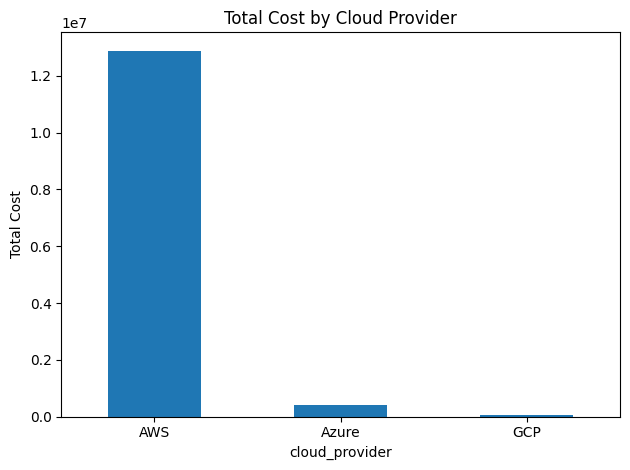

In [16]:
#Total cost by cloud provider
provider_cost = df.groupby("cloud_provider")["actual_cost"].sum()

provider_cost.plot(kind="bar", title="Total Cost by Cloud Provider")
plt.ylabel("Total Cost")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

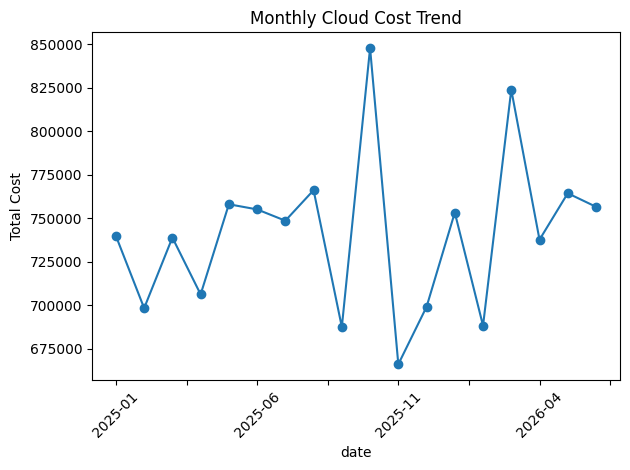

In [17]:
#Monthly cloud cost trend
df["date"] = pd.to_datetime(df["date"])

monthly_cost = df.groupby(
    df["date"].dt.to_period("M")
)["actual_cost"].sum()

monthly_cost.index = monthly_cost.index.astype(str)

monthly_cost.plot(kind="line", marker="o", title="Monthly Cloud Cost Trend")
plt.ylabel("Total Cost")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

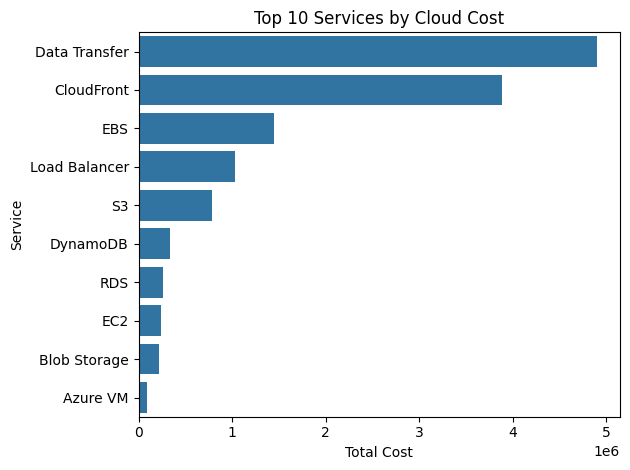

In [18]:
#Top 10 Executive services
service_cost = (
    df.groupby("service")["actual_cost"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

sns.barplot(x=service_cost.values, y=service_cost.index)
plt.title("Top 10 Services by Cloud Cost")
plt.xlabel("Total Cost")
plt.ylabel("Service")
plt.tight_layout()
plt.show()

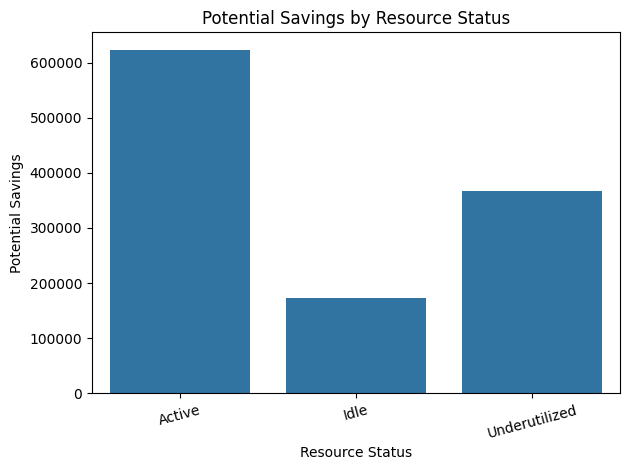

In [20]:
#Potential saving by Resource Status
savings = df.groupby("resource_status")["potential_savings"].sum()

sns.barplot(x=savings.index, y=savings.values)
plt.title("Potential Savings by Resource Status")
plt.xlabel("Resource Status")
plt.ylabel("Potential Savings")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

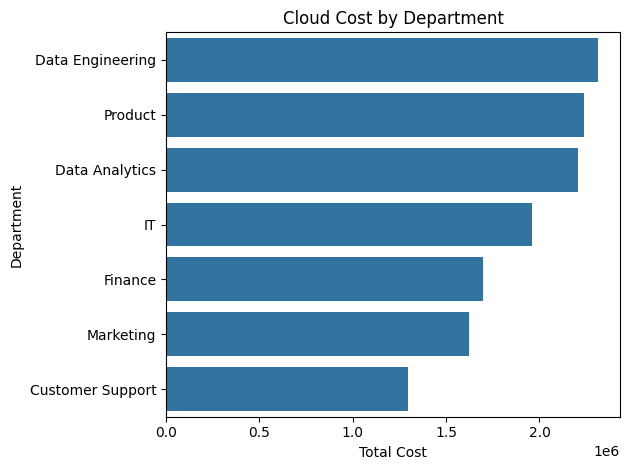

In [21]:
#Cloud cost by Department
dept_cost = (
    df.groupby("department")["actual_cost"]
    .sum()
    .sort_values(ascending=False)
)

sns.barplot(x=dept_cost.values, y=dept_cost.index)
plt.title("Cloud Cost by Department")
plt.xlabel("Total Cost")
plt.ylabel("Department")
plt.tight_layout()
plt.show()

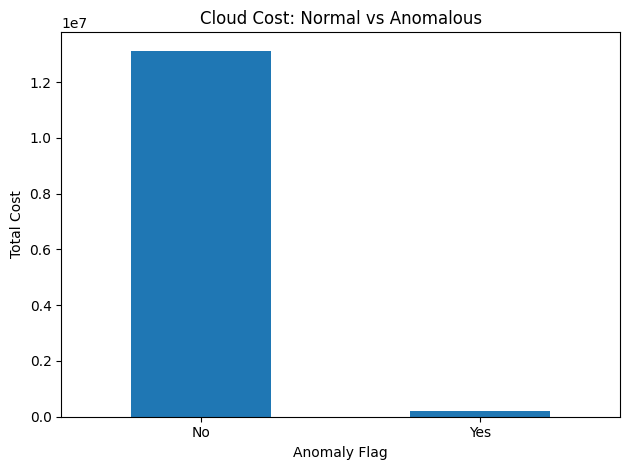

In [22]:
#Anomaly Analysis
anomaly_cost = df.groupby("anomaly_flag")["actual_cost"].sum()

anomaly_cost.plot(
    kind="bar",
    title="Cloud Cost: Normal vs Anomalous"
)
plt.xlabel("Anomaly Flag")
plt.ylabel("Total Cost")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

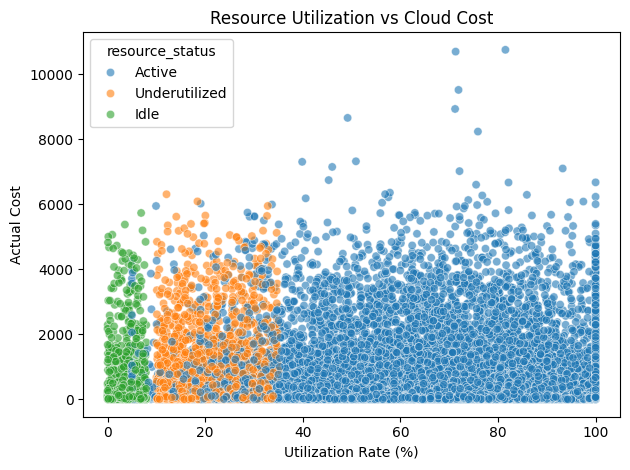

In [24]:
#Resource utilization vs Cloud cost
sns.scatterplot(
    data=df,
    x="utilization_rate",
    y="actual_cost",
    hue="resource_status",
    alpha=0.6
)

plt.title("Resource Utilization vs Cloud Cost")
plt.xlabel("Utilization Rate (%)")
plt.ylabel("Actual Cost")
plt.tight_layout()
plt.show()

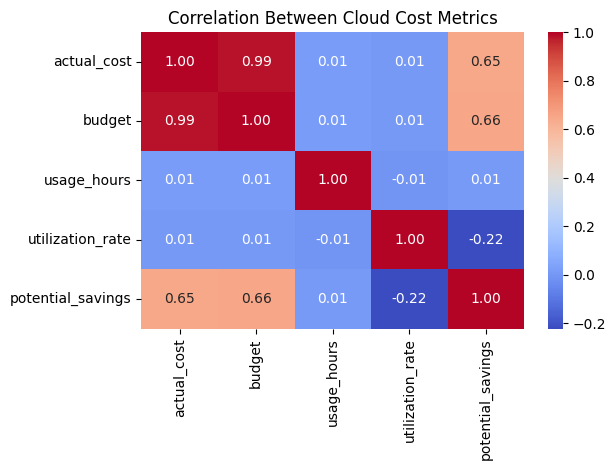

In [26]:
#Correlation between numeric column
numeric_cols = [
    "actual_cost",
    "budget",
    "usage_hours",
    "utilization_rate",
    "potential_savings"
]

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Cloud Cost Metrics")
plt.tight_layout()
plt.show()